# 02 · Exploratory Data Analysis

**Objective.** Describe how NYC taxi trips behaved in 2025 — when they happen, where they start and end, how
long they take and what they cost — and turn those patterns into concrete modelling decisions.

**Scope.** The 45.07 M cleaned records produced in Phase 2 (`data/processed/taxi_features_2025.parquet`), which
already carry zone geometry, weather and holiday flags. Nothing here is used to choose a test set; every
observation informs features or cleaning choices that are still validated chronologically.

**Method.** Aggregations run inside DuckDB over Parquet, so a full-year scan costs seconds and no query loads
45 M rows into memory. Only plotting samples are materialised in Pandas.

**Dual axes.** Yellow carries roughly 80× the trips of Green, so any chart that compares raw counts uses two
y-axes: **left = Yellow, right = Green**, each colour-coded to match its series. Compare the *shape* of the two
distributions, not the height of the bars — the axes are scaled independently.

**How to read this notebook.** Every figure is followed by an interpretation that says what it shows and what it
changes about the model. Where a pattern could tempt a leaky feature (fare, distance, drop-off time), that
temptation is named explicitly.

## 1. Setup

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter
from IPython.display import display

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "outputs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

FEATURES = PROCESSED / "taxi_features_2025.parquet"
SEED = 33
COLORS = {"yellow": "#D6A900", "green": "#168A62"}

con = duckdb.connect()
con.execute("SET threads TO 4")
con.execute("SET memory_limit = '6GB'")

def q(sql):
    # Run a query and return a DataFrame; every heavy step stays inside DuckDB.
    return con.execute(sql).df()

def parquet(path=FEATURES):
    return f"read_parquet('{path}')"

from matplotlib.patches import Patch

def dual_overlay(ax, yellow_values, green_values, bins, xlabel, title, ylabel="trips"):
    # Yellow carries ~80x the trips of Green, so one shared count axis hides Green completely.
    # Each service gets its own colour-coded y-axis instead.
    ax.hist(yellow_values, bins=bins, color=COLORS["yellow"], alpha=0.85)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(f"Yellow {ylabel} (left)", color="#8a6d00")
    ax.tick_params(axis="y", colors="#8a6d00")
    twin = ax.twinx()
    twin.hist(green_values, bins=bins, color=COLORS["green"], alpha=0.8)
    twin.set_ylabel(f"Green {ylabel} (right)", color="#0f6b4a")
    twin.tick_params(axis="y", colors="#0f6b4a")
    twin.grid(False)
    ax.set_title(title)
    ax.legend(handles=[Patch(color=COLORS["yellow"], label="yellow (left axis)"),
                       Patch(color=COLORS["green"], label="green (right axis)")], loc="upper right")
    return twin

rows = q(f"SELECT count(*) AS trips FROM {parquet()}").iloc[0, 0]
print(f"{rows:,} trips loaded from {FEATURES.name}")

45,071,006 trips loaded from taxi_features_2025.parquet


## 2. Temporal patterns

Demand and speed are the two quantities a duration model must capture. Demand shows up as volume; speed shows
up as median duration. Both move on hourly, weekly and monthly cycles, and the cycles interact — a Tuesday at
8 am is not a Sunday at 8 am.

taxi_type,green,yellow
month,,
1,46135,3269968
2,44190,3336057
3,48579,3850861
4,49225,3684465
5,52322,4127946
6,46382,3907318
7,45673,3527880
8,43516,3196016
9,46335,3868292


taxi_type,green,yellow
month,,
1,11.47,11.73
2,11.73,12.20
3,12.35,12.53
4,12.63,13.02
5,12.93,14.02
6,12.90,13.73
7,12.90,13.67
8,13.28,13.58
9,13.85,14.68


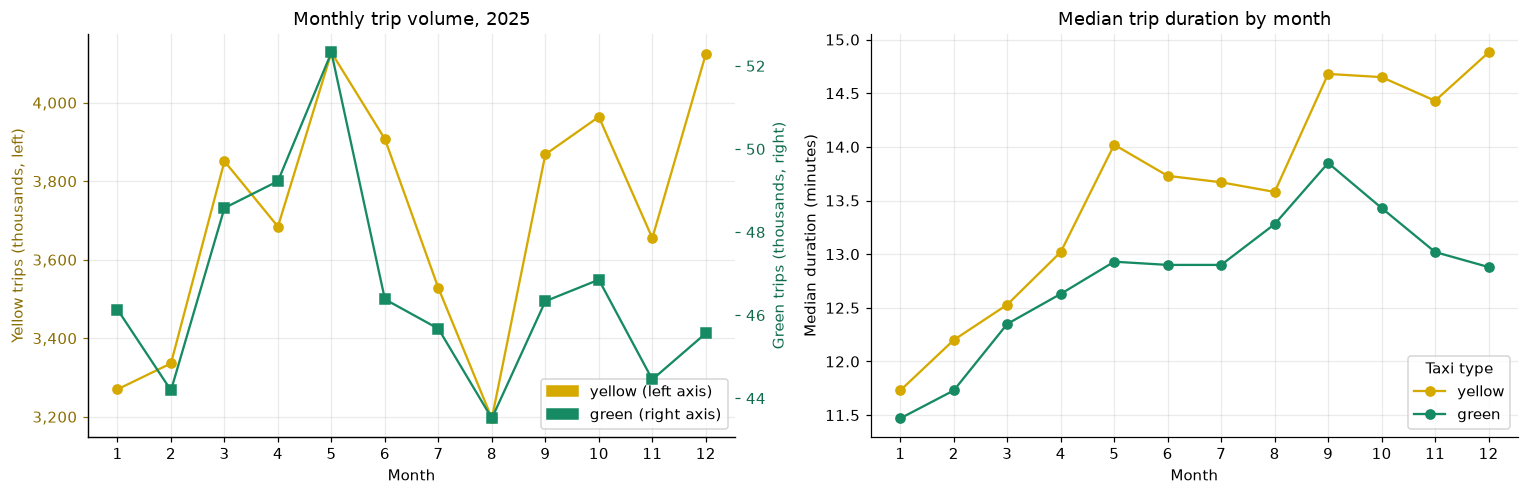

Yellow median duration: 11.73 min in month 1 -> 14.88 min in month 12 (27% slower)
Green median duration:  11.47 min -> 13.85 min
Yellow volume: lowest 3,196,016 (month 8), highest 4,127,946 (month 5)


In [2]:
monthly = q(f'''
    SELECT month, taxi_type, count(*) AS trips, round(median(duration_min), 2) AS median_duration,
           round(median(fare_amount), 2) AS median_fare
    FROM {parquet()} GROUP BY 1, 2 ORDER BY 1, 2
''')
display(monthly.pivot(index="month", columns="taxi_type", values="trips").round(0).astype("Int64"))
display(monthly.pivot(index="month", columns="taxi_type", values="median_duration").round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
yellow_monthly = monthly[monthly.taxi_type == "yellow"]
green_monthly = monthly[monthly.taxi_type == "green"]

# Volume differs by two orders of magnitude, so volume gets twin axes; duration shares one axis.
volume_ax = axes[0]
volume_ax.plot(yellow_monthly.month, yellow_monthly.trips / 1000, marker="o",
               color=COLORS["yellow"], label="yellow (left axis)")
volume_ax.set_xlabel("Month")
volume_ax.set_ylabel("Yellow trips (thousands, left)", color="#8a6d00")
volume_ax.tick_params(axis="y", colors="#8a6d00")
volume_twin = volume_ax.twinx()
volume_twin.plot(green_monthly.month, green_monthly.trips / 1000, marker="s",
                 color=COLORS["green"], label="green (right axis)")
volume_twin.set_ylabel("Green trips (thousands, right)", color="#0f6b4a")
volume_twin.tick_params(axis="y", colors="#0f6b4a")
volume_twin.grid(False)
volume_ax.set_title("Monthly trip volume, 2025")
volume_ax.legend(handles=[Patch(color=COLORS["yellow"], label="yellow (left axis)"),
                          Patch(color=COLORS["green"], label="green (right axis)")], loc="lower right")

for service in ("yellow", "green"):
    subset = monthly[monthly.taxi_type == service]
    axes[1].plot(subset.month, subset.median_duration, marker="o", label=service, color=COLORS[service])
axes[1].set(title="Median trip duration by month", xlabel="Month", ylabel="Median duration (minutes)")
axes[1].legend(title="Taxi type", loc="lower right")
for ax in (volume_ax, axes[1]):
    ax.set_xticks(range(1, 13))
volume_ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
volume_twin.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
fig.tight_layout()
fig.savefig(FIGURES / "02_monthly_volume_duration.png", bbox_inches="tight")
plt.show()

yellow = monthly[monthly.taxi_type == "yellow"].set_index("month")
green = monthly[monthly.taxi_type == "green"].set_index("month")
print(f"Yellow median duration: {yellow.median_duration.min():.2f} min in month "
      f"{yellow.median_duration.idxmin()} -> {yellow.median_duration.max():.2f} min in month "
      f"{yellow.median_duration.idxmax()} ({100*(yellow.median_duration.max()/yellow.median_duration.min()-1):.0f}% slower)")
print(f"Green median duration:  {green.median_duration.min():.2f} min -> {green.median_duration.max():.2f} min")
print(f"Yellow volume: lowest {yellow.trips.min():,} (month {yellow.trips.idxmin()}), "
      f"highest {yellow.trips.max():,} (month {yellow.trips.idxmax()})")

**Reading the volume panel:** the right axis (Green) spans roughly 44–52k trips while the left (Yellow) spans
3.2–4.1M, so the two lines must be read against their own axes — Green never approaches Yellow's volume.
Twin axes are used because a shared scale flattens Green to a horizontal line.

**Interpretation.** Yellow volume swings by about a quarter around the year — May and December are the busiest
months, August the quietest — while Green barely moves, which fits a small fleet serving local demand rather
than a large fleet chasing citywide demand.

The more consequential pattern is the duration drift: Yellow's median rises from **11.73 minutes in January to
14.88 in December**, a **27% increase**, with only a small dip in November. Green follows the same direction but
from ~11.5 to ~12.9 minutes. This is a warning for the chronological split (Jan–Aug train, Sep–Oct validation,
Nov–Dec test): the test months are structurally slower than the training months, so test errors will look worse
than validation errors even if the model is unchanged. That is a property of the data, not a defect, and it will
be reported rather than tuned away.

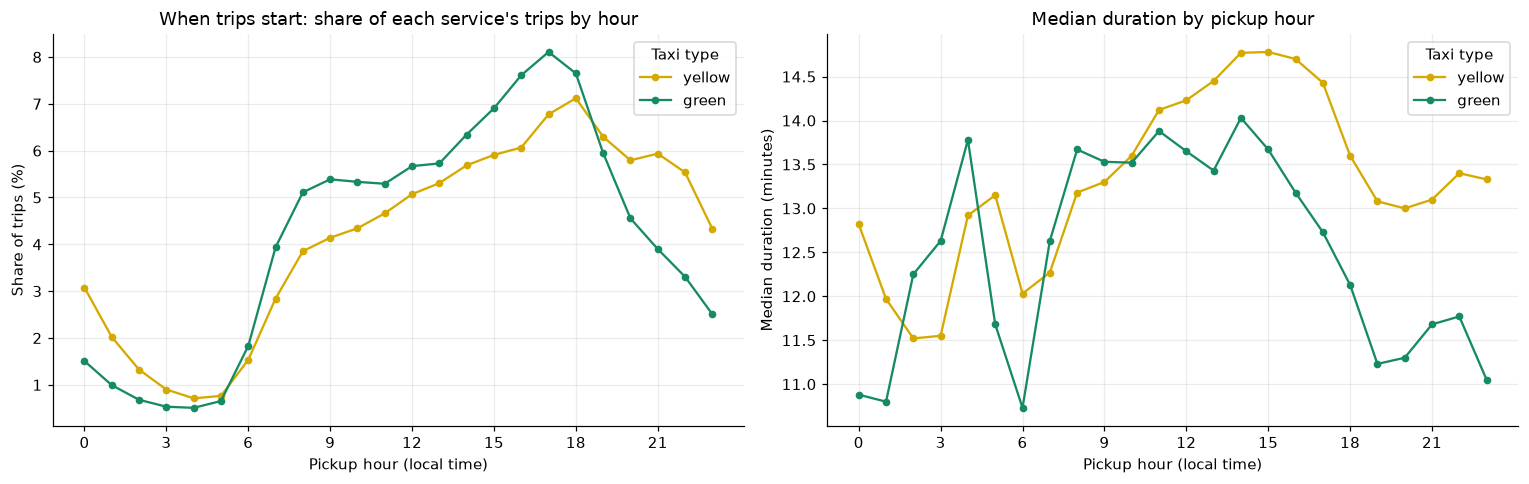

,taxi_type,hour,trips,median_duration,metric
17,green,17,45337,12.73,busiest hour
42,yellow,18,3169019,13.60,busiest hour


,taxi_type,hour,trips,median_duration,metric
14,green,14,35480,14.03,slowest hour
39,yellow,15,2630448,14.78,slowest hour


,trips,median_duration
hour,,
6,682662,12.03
7,1265095,12.27
8,1715015,13.18
9,1843015,13.30
12,2256913,14.23
15,2630448,14.78
17,3015585,14.43
18,3169019,13.60
21,2642355,13.10


In [3]:
hourly = q(f'''
    SELECT taxi_type, pickup_hour_of_day AS hour, count(*) AS trips,
           round(median(duration_min), 2) AS median_duration
    FROM {parquet()} GROUP BY 1, 2 ORDER BY 1, 2
''')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for service in ("yellow", "green"):
    subset = hourly[hourly.taxi_type == service].sort_values("hour")
    share = 100 * subset.trips / subset.trips.sum()
    axes[0].plot(subset.hour, share, marker="o", ms=4, label=service, color=COLORS[service])
    axes[1].plot(subset.hour, subset.median_duration, marker="o", ms=4, label=service, color=COLORS[service])
axes[0].set(title="When trips start: share of each service's trips by hour",
            xlabel="Pickup hour (local time)", ylabel="Share of trips (%)")
axes[1].set(title="Median duration by pickup hour", xlabel="Pickup hour (local time)",
            ylabel="Median duration (minutes)")
axes[0].set_xticks(range(0, 24, 3)); axes[1].set_xticks(range(0, 24, 3))
for ax in axes:
    ax.legend(title="Taxi type")
fig.tight_layout()
fig.savefig(FIGURES / "02_hourly_profile.png", bbox_inches="tight")
plt.show()

display(hourly.loc[hourly.groupby("taxi_type").trips.idxmax()].assign(metric="busiest hour"))
display(hourly.loc[hourly.groupby("taxi_type").median_duration.idxmax()].assign(metric="slowest hour"))
display(hourly[hourly.taxi_type == "yellow"].set_index("hour")
        .loc[[6, 7, 8, 9, 12, 15, 17, 18, 21, 23], ["trips", "median_duration"]])

**Interpretation.** Yellow demand is evening-heavy: 5–6 pm is the single busiest period, with a smaller midday
shoulder, while the morning commute is comparatively flat. Green peaks an hour earlier and decays faster,
consistent with shorter outer-borough trips.

Duration and volume do **not** peak together. Yellow's median duration is highest at **3–4 pm (14.78 and 14.70
minutes)** — before the volume peak — and drops in the evening as demand rises. The busiest hour (6 pm) has a
median of 13.60 minutes, below the afternoon maximum. Volume and slowness are related but not interchangeable,
which is why the model needs hour, weekday and their interaction rather than one "busy" flag.

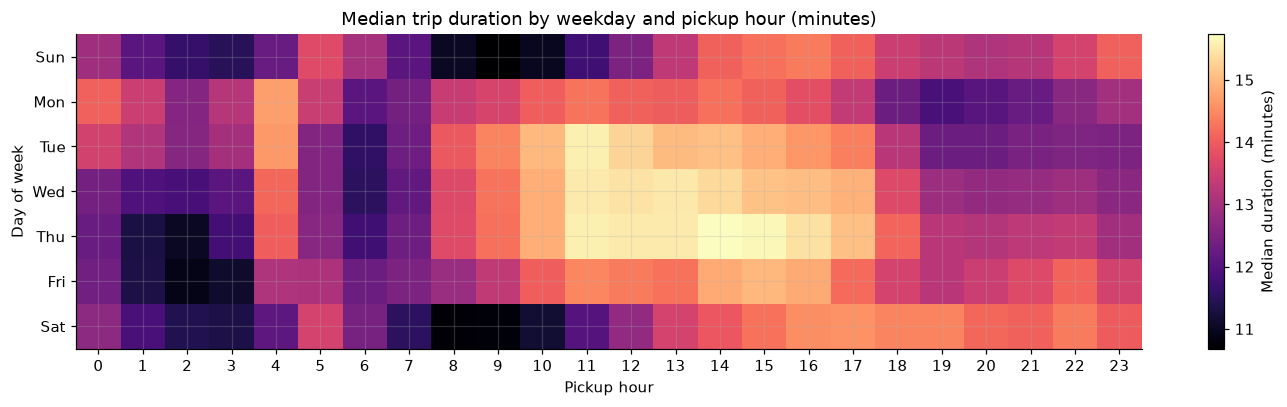

hour,0,6,8,12,17,21
Sun,12.9,13.0,11.0,12.5,14.1,13.2
Mon,14.0,12.1,13.4,14.1,13.4,12.2
Tue,13.6,11.6,14.0,15.3,14.4,12.5
Wed,12.4,11.5,13.7,15.4,14.9,12.8
Thu,12.3,11.8,13.7,15.5,15.1,13.3
Fri,12.4,12.3,12.9,14.3,14.2,13.7
Sat,12.7,12.4,10.8,12.8,14.6,14.1


slowest cell: ('Thu', np.int8(14)) 15.7 min
fastest cell: ('Sun', np.int8(9)) 10.7 min


In [4]:
grid = q(f'''
    SELECT day_of_week, pickup_hour_of_day AS hour, median(duration_min) AS median_duration, count(*) AS trips
    FROM {parquet()} GROUP BY 1, 2
''')
pivot = grid.pivot(index="day_of_week", columns="hour", values="median_duration")
pivot.index = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]

fig, ax = plt.subplots(figsize=(13, 3.8))
image = ax.imshow(pivot.to_numpy(), aspect="auto", cmap="magma")
ax.set_xticks(range(24)); ax.set_xticklabels(range(24))
ax.set_yticks(range(7)); ax.set_yticklabels(pivot.index)
ax.set(title="Median trip duration by weekday and pickup hour (minutes)",
       xlabel="Pickup hour", ylabel="Day of week")
bar = fig.colorbar(image, ax=ax)
bar.set_label("Median duration (minutes)")
fig.tight_layout()
fig.savefig(FIGURES / "02_weekday_hour_heatmap.png", bbox_inches="tight")
plt.show()

display(pivot.round(1).loc[:, [0, 6, 8, 12, 17, 21]])
print("slowest cell:", pivot.stack().idxmax(), f"{pivot.stack().max():.1f} min")
print("fastest cell:", pivot.stack().idxmin(), f"{pivot.stack().min():.1f} min")

**Interpretation.** The heat map shows that slowness is a **weekday daytime** phenomenon, not only a rush-hour
one: the darkest cells are Wednesday and Thursday from midday to late afternoon, peaking at **15.7 minutes at
2 pm on Thursday**. Weekday mornings are consistently slower than weekend mornings — Tuesday at 8 am is 14.0
minutes against 10.8 on Saturday — and Saturday evenings are slow for a different reason: fewer cars, longer
waits.

A single `is_rush_hour` flag would average across all of this. Hour, weekday, and their combination carry real
structure, and the interaction is the argument for keeping time-of-day cyclical rather than as a raw integer.

## 3. Duration

Duration is the stage-1 target. Its shape decides the loss function, the cleaning window and which metric should
lead model selection.

,taxi_type,p10,p25,p50,p75,p90,p99,mean,sd
0,green,5.5,8.4,12.8,19.3,29.3,64.3,15.99,12.58
1,yellow,5.3,8.4,13.6,21.5,32.8,70.4,17.20,13.59


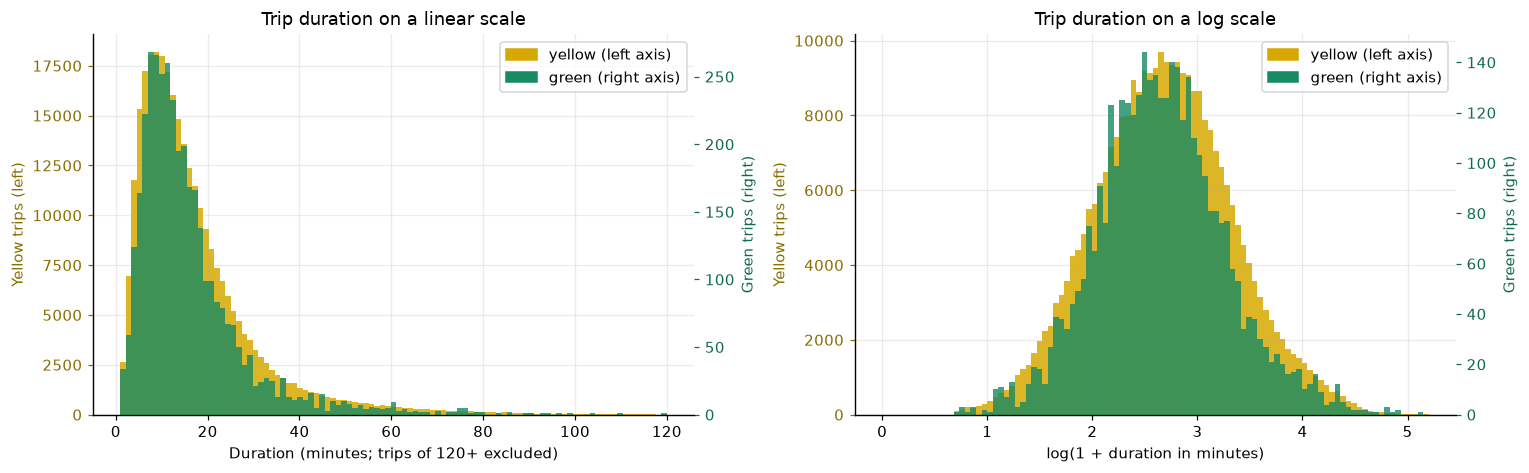

In [5]:
stats = q(f'''
    SELECT taxi_type,
           round(quantile_cont(duration_min, 0.10), 1) AS p10,
           round(quantile_cont(duration_min, 0.25), 1) AS p25,
           round(median(duration_min), 1) AS p50,
           round(quantile_cont(duration_min, 0.75), 1) AS p75,
           round(quantile_cont(duration_min, 0.90), 1) AS p90,
           round(quantile_cont(duration_min, 0.99), 1) AS p99,
           round(avg(duration_min), 2) AS mean,
           round(stddev_samp(duration_min), 2) AS sd
    FROM {parquet()} GROUP BY 1 ORDER BY 1
''')
display(stats)

sample = q(f"SELECT taxi_type, duration_min FROM {parquet()} USING SAMPLE 300000 ROWS (reservoir, {SEED})")
yellow_sample = sample[sample.taxi_type == "yellow"].duration_min
green_sample = sample[sample.taxi_type == "green"].duration_min

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
dual_overlay(axes[0], yellow_sample[yellow_sample < 120], green_sample[green_sample < 120],
             np.linspace(1, 120, 100), "Duration (minutes; trips of 120+ excluded)",
             "Trip duration on a linear scale")
dual_overlay(axes[1], np.log1p(yellow_sample), np.log1p(green_sample), np.linspace(0, 5.2, 100),
             "log(1 + duration in minutes)", "Trip duration on a log scale")
fig.tight_layout()
fig.savefig(FIGURES / "02_duration_distribution.png", bbox_inches="tight")
plt.show()

**Interpretation.** Duration is right-skewed with a heavy shoulder. Yellow's median is **13.6 minutes** but its
mean is **17.2** and its standard deviation **13.6**; the 99th percentile reaches **70.4 minutes**. Green is
modestly faster and tighter (median 12.8, mean 16.0, p99 64.3).

Two consequences. First, MAE in minutes will be dominated by long trips, so model comparison should report
median absolute error alongside MAE. Second, the log view is close to symmetric, making `log1p(duration)` a
sensible training target to test — it stops a handful of very long trips from steering the fit.

In [6]:
buckets = q(f'''
    SELECT CASE
             WHEN duration_min < 5 THEN '0-5 min'
             WHEN duration_min < 10 THEN '5-10 min'
             WHEN duration_min < 15 THEN '10-15 min'
             WHEN duration_min < 20 THEN '15-20 min'
             WHEN duration_min < 30 THEN '20-30 min'
             WHEN duration_min < 60 THEN '30-60 min'
             ELSE '60+ min' END AS bucket,
           taxi_type, count(*) AS trips, round(median(fare_amount), 2) AS median_fare
    FROM {parquet()} GROUP BY 1, 2 ORDER BY 1, 2
''')
order = ["0-5 min", "5-10 min", "10-15 min", "15-20 min", "20-30 min", "30-60 min", "60+ min"]
pivot = buckets.pivot(index="bucket", columns="taxi_type", values="trips").reindex(order)
display((100 * pivot / pivot.sum()).round(1))
display(buckets.pivot(index="bucket", columns="taxi_type", values="median_fare").reindex(order).round(2))
print("share finishing within 15 min:",
      (100 * pivot.loc[order[:3]].sum() / pivot.sum()).round(1).to_dict())

taxi_type,green,yellow
bucket,,
0-5 min,7.7,8.7
5-10 min,26.4,24.6
10-15 min,26.5,22.3
15-20 min,16.0,15.8
20-30 min,13.8,16.3
30-60 min,8.0,10.4
60+ min,1.5,1.9


taxi_type,green,yellow
bucket,,
0-5 min,6.5,5.80
5-10 min,9.3,9.30
10-15 min,13.5,13.05
15-20 min,17.7,17.70
20-30 min,24.7,24.70
30-60 min,37.5,43.60
60+ min,5.8,70.00


share finishing within 15 min: {'green': 60.6, 'yellow': 55.6}


**Interpretation.** **56% of Yellow trips and 61% of Green trips finish within 15 minutes**, and only 1.9% and
1.5% exceed an hour. The heavy tail is a small share of the population but a large share of the absolute error.

The fare rows hold a genuine data-quality warning rather than a clean monotone curve. For Yellow, median fare
rises steadily with duration (\$5.80 → \$70.00, the last bucket being JFK flat fares). For Green it rises to
\$37.50 and then **collapses to \$5.80 in the 60+ minute bucket** — those long trips have a median total of
\$56.73 and a median distance of 13.1 miles, so the fare field itself is under-recorded, not the trip. That is
checked explicitly in Section 5.

## 4. Geography

Zone geography is the only route information available before a trip starts. These views establish where demand
sits, how often trips cross boroughs, and how well zone-centroid geometry proxies the distance a meter records.

,pu_zone_name,pu_borough,taxi_type,trips,share_pct
0,East Harlem North,Manhattan,green,"142,645",25.51
1,East Harlem South,Manhattan,green,"81,995",14.66
2,Central Park,Manhattan,green,"27,316",4.88
3,Morningside Heights,Manhattan,green,"26,040",4.66
4,Forest Hills,Queens,green,"25,722",4.60
5,Central Harlem,Manhattan,green,"22,865",4.09
6,Elmhurst,Queens,green,"20,469",3.66
7,Fort Greene,Brooklyn,green,"19,570",3.50
8,Jamaica,Queens,green,"16,765",3.00
9,Downtown Brooklyn/MetroTech,Brooklyn,green,"15,740",2.81


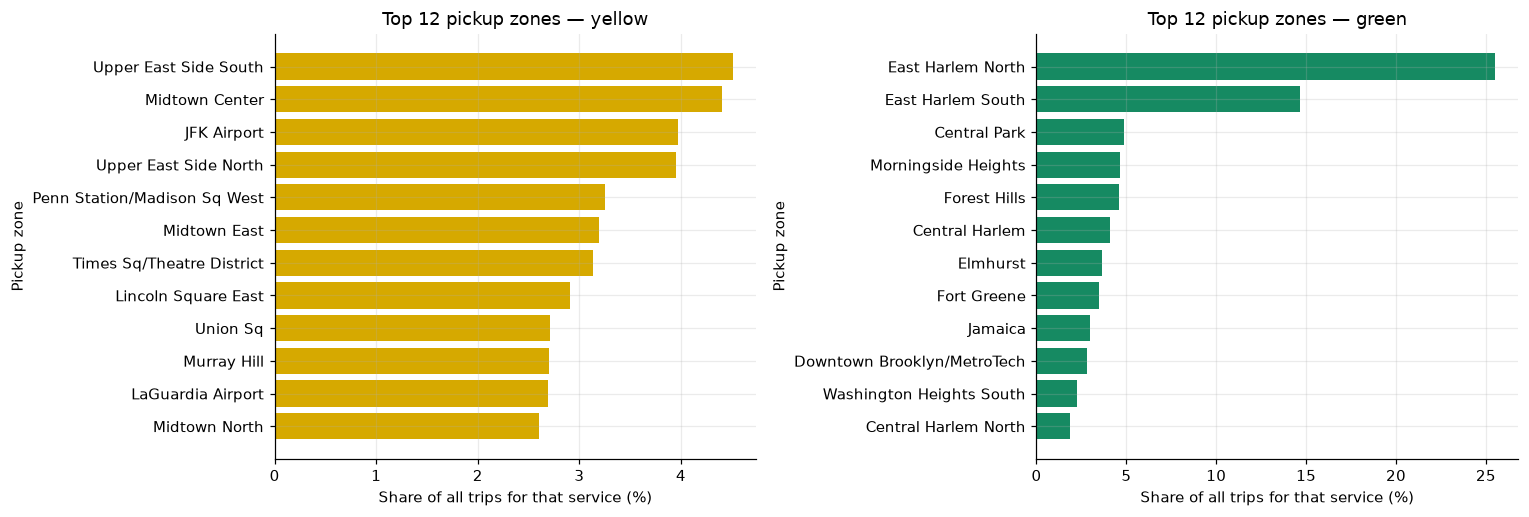

In [7]:
top_pu = q(f'''
    SELECT pu_zone_name, pu_borough, taxi_type, count(*) AS trips
    FROM {parquet()} GROUP BY 1, 2, 3
    QUALIFY row_number() OVER (PARTITION BY taxi_type ORDER BY trips DESC) <= 12
    ORDER BY taxi_type, trips DESC
''')
totals = q(f"SELECT taxi_type, count(*) AS total FROM {parquet()} GROUP BY 1").set_index("taxi_type").total
top_pu["share_pct"] = 100 * top_pu.trips / top_pu.taxi_type.map(totals)
display(top_pu.assign(trips=lambda d: d.trips.map("{:,}".format)).round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, service in zip(axes, ("yellow", "green")):
    subset = top_pu[top_pu.taxi_type == service].sort_values("share_pct")
    ax.barh(subset.pu_zone_name, subset.share_pct, color=COLORS[service])
    ax.set(title=f"Top 12 pickup zones — {service}", xlabel="Share of all trips for that service (%)",
           ylabel="Pickup zone")
fig.tight_layout()
fig.savefig(FIGURES / "02_top_pickup_zones.png", bbox_inches="tight")
plt.show()

**Interpretation.** The two fleets serve different parts of the city, but not in the simplistic "Green is Queens"
way one might expect. Yellow is Manhattan-core and airports: Upper East Side South and Midtown Center are the two
largest zones (about 4.5% and 4.4% of Yellow trips each), followed by JFK and Upper East Side North, then Penn
Station.

Green concentrates in **Upper Manhattan and the outer boroughs** — East Harlem North alone is **25.5%** of Green
trips, followed by East Harlem South (14.7%), Central Park and Morningside Heights (~4.9% and 4.7%), then Queens
zones (Forest Hills 4.6%, Elmhurst 3.7%) and Brooklyn zones (Fort Greene 3.5%). That geography follows the Boro
Taxi rule: Green may pick up in Manhattan only north of the CBD, which the next table quantifies.

Because the top zones differ so strongly, a pooled model that ignored taxi type would learn a Manhattan-shaped
concept of a trip and apply it to Queens. Per-service reporting and `taxi_type` as a feature both follow from
this figure.

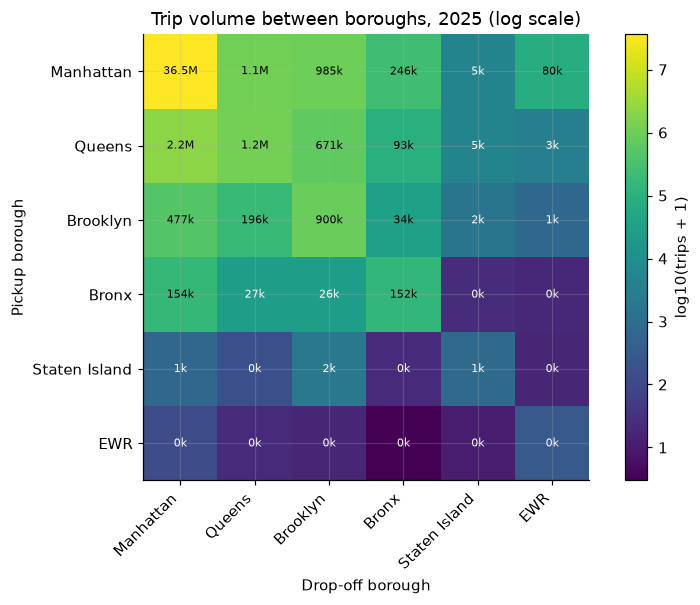

,pu_borough,do_borough,trips,median_duration,share_pct
28,Manhattan,Manhattan,36484199,11.8,80.95
0,Queens,Manhattan,2189717,39.0,4.86
20,Queens,Queens,1204405,16.1,2.67
10,Manhattan,Queens,1132312,31.7,2.51
21,Manhattan,Brooklyn,985410,27.1,2.19
29,Brooklyn,Brooklyn,900486,18.1,2.00
11,Queens,Brooklyn,671081,35.5,1.49
23,Brooklyn,Manhattan,477110,27.3,1.06
12,Manhattan,Bronx,245760,28.1,0.55
1,Brooklyn,Queens,195660,28.9,0.43


intra-Manhattan share of all trips: 80.95


In [8]:
flows = q(f'''
    SELECT pu_borough, do_borough, count(*) AS trips,
           round(median(duration_min), 1) AS median_duration
    FROM {parquet()} GROUP BY 1, 2
''')
matrix = flows.pivot(index="pu_borough", columns="do_borough", values="trips").fillna(0)
order = matrix.sum(axis=1).sort_values(ascending=False).index
matrix = matrix.loc[order, order]

fig, ax = plt.subplots(figsize=(7.6, 5.6))
image = ax.imshow(np.log10(matrix.to_numpy() + 1), cmap="viridis")
ax.set_xticks(range(len(matrix.columns))); ax.set_xticklabels(matrix.columns, rotation=45, ha="right")
ax.set_yticks(range(len(matrix.index))); ax.set_yticklabels(matrix.index)
ax.set(title="Trip volume between boroughs, 2025 (log scale)", xlabel="Drop-off borough",
       ylabel="Pickup borough")
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        value = matrix.iloc[i, j]
        ax.text(j, i, f"{value/1e6:.1f}M" if value >= 1e6 else (f"{value/1e3:.0f}k" if value else ""),
                ha="center", va="center", fontsize=7,
                color="white" if np.log10(value + 1) < 4.5 else "black")
bar = fig.colorbar(image, ax=ax)
bar.set_label("log10(trips + 1)")
fig.tight_layout()
fig.savefig(FIGURES / "02_borough_flows.png", bbox_inches="tight")
plt.show()

share = flows.copy()
share["share_pct"] = 100 * share.trips / share.trips.sum()
display(share.sort_values("trips", ascending=False).head(10).round(2))
print("intra-Manhattan share of all trips:",
      round(float(share[(share.pu_borough == 'Manhattan') & (share.do_borough == 'Manhattan')].share_pct.iloc[0]), 2))

**Interpretation.** The matrix is strongly diagonal, and one cell dominates everything: **Manhattan → Manhattan
is 81% of all trips**. The largest off-diagonal flows are the airport corridors — Queens → Manhattan (4.9%) and
Manhattan → Queens (2.5%) — followed by Manhattan ↔ Brooklyn (~2.2% each way).

Two modelling implications. First, trips crossing boroughs are systematically long: Queens → Manhattan has a
median duration of 39 minutes against 11.8 inside Manhattan, so borough pair and `cross_borough` belong in the
feature set. Second, the long tail of thin cells (Staten Island, Bronx ↔ Brooklyn) is a bias risk: even 45 M
trips leave few examples there, so per-borough error reporting is required rather than optional.

,band,trips,median_duration,median_min_per_km
0,0-1 km,3636119,6.3,529.1
1,1-2 km,12614464,8.9,360.9
2,2-4 km,13602464,14.0,299.1
3,4-8 km,7843763,21.3,234.7
4,8-16 km,3770992,30.3,173.6
5,16+ km,1925753,50.5,151.6


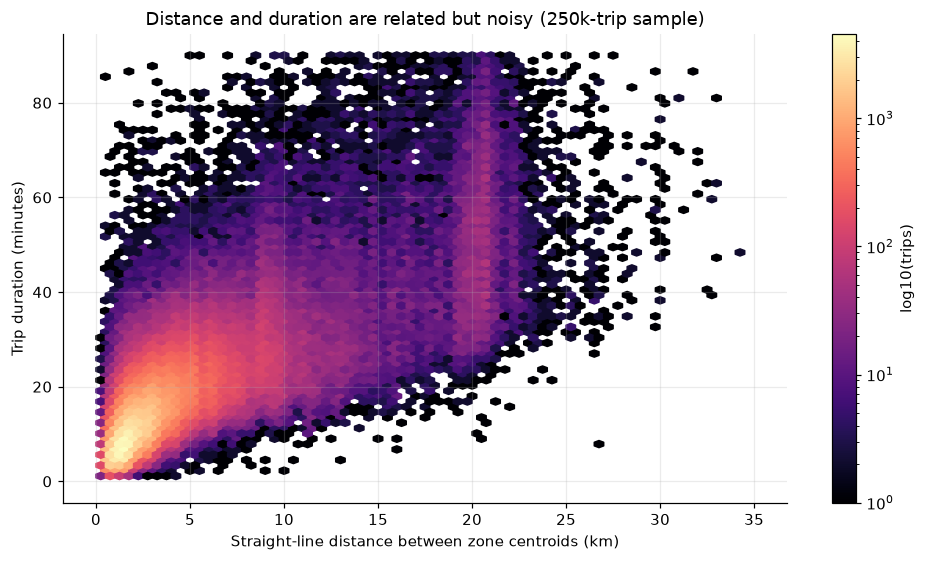

In [9]:
distance_bands = q(f'''
    SELECT CASE
             WHEN haversine_km < 1 THEN '0-1 km'
             WHEN haversine_km < 2 THEN '1-2 km'
             WHEN haversine_km < 4 THEN '2-4 km'
             WHEN haversine_km < 8 THEN '4-8 km'
             WHEN haversine_km < 16 THEN '8-16 km'
             ELSE '16+ km' END AS band,
           count(*) AS trips,
           round(median(duration_min), 1) AS median_duration,
           round(median(duration_min * 60 / haversine_km), 1) AS median_min_per_km
    FROM {parquet()} WHERE haversine_km > 0 GROUP BY 1
    ORDER BY min(haversine_km)
''')
display(distance_bands)

sample = q(f'''
    SELECT haversine_km, duration_min FROM {parquet()}
    WHERE haversine_km > 0.2 AND haversine_km < 35 USING SAMPLE 250000 ROWS (reservoir, {SEED})
''')
fig, ax = plt.subplots(figsize=(9, 5.2))
image = ax.hexbin(sample.haversine_km, sample.duration_min, gridsize=70, cmap="magma", bins="log",
                  extent=(0, 35, 0, 90))
ax.set(title="Distance and duration are related but noisy (250k-trip sample)",
       xlabel="Straight-line distance between zone centroids (km)",
       ylabel="Trip duration (minutes)")
bar = fig.colorbar(image, ax=ax)
bar.set_label("log10(trips)")
fig.tight_layout()
fig.savefig(FIGURES / "02_distance_vs_duration.png", bbox_inches="tight")
plt.show()

**Interpretation.** Median duration climbs from 6.3 minutes under 1 km to 50.5 minutes beyond 16 km, so geometry
carries strong signal. But the cloud is broad: at any distance, durations vary by a factor of two or more
because of traffic, hour and routing.

Minutes per kilometre falls from about 300 (2–4 km) to 152 (16+ km), the expected side-street versus arterial
effect. The 0–1 km row shows an implausible ~529 min/km, which is an artefact of dividing by a near-zero
denominator — centroid distance between adjacent zones can be a few dozen metres — so that row should be read as
"very short, slow trips", not as a speed.

Two conclusions: distance is necessary but far from sufficient, and a linear model on distance will be badly
specified, favouring trees that can model the interaction with hour and zone.

## 5. Fare structure

Stage 2 predicts `fare_amount`, the metered fare before tips and tolls. Understanding its shape — including the
airport flat fares and the surcharge regime — determines what is predictable and what is not.

,taxi_type,p05,p25,p50,p75,p95,p99,mean,trips
0,green,5.1,9.30,13.50,20.5,43.60,75.1,17.66,559224
1,yellow,5.8,9.32,14.21,23.3,56.18,70.2,19.67,44511782


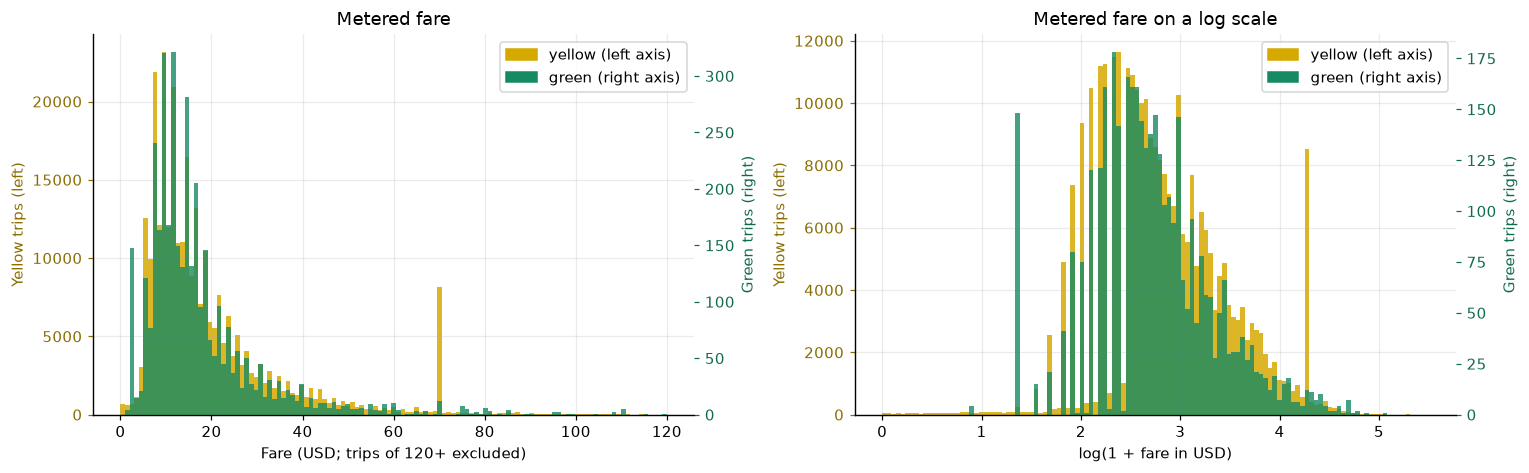

In [10]:
fare_stats = q(f'''
    SELECT taxi_type,
           round(quantile_cont(fare_amount, 0.05), 2) AS p05,
           round(quantile_cont(fare_amount, 0.25), 2) AS p25,
           round(median(fare_amount), 2) AS p50,
           round(quantile_cont(fare_amount, 0.75), 2) AS p75,
           round(quantile_cont(fare_amount, 0.95), 2) AS p95,
           round(quantile_cont(fare_amount, 0.99), 2) AS p99,
           round(avg(fare_amount), 2) AS mean,
           count(*) AS trips
    FROM {parquet()} GROUP BY 1 ORDER BY 1
''')
display(fare_stats)

sample = q(f"SELECT taxi_type, fare_amount FROM {parquet()} USING SAMPLE 300000 ROWS (reservoir, {SEED + 1})")
yellow_fare = sample[sample.taxi_type == "yellow"].fare_amount
green_fare = sample[sample.taxi_type == "green"].fare_amount

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
dual_overlay(axes[0], yellow_fare[yellow_fare < 120], green_fare[green_fare < 120],
             np.linspace(0, 120, 120), "Fare (USD; trips of 120+ excluded)", "Metered fare")
dual_overlay(axes[1], np.log1p(yellow_fare), np.log1p(green_fare), np.linspace(0, 5.5, 120),
             "log(1 + fare in USD)", "Metered fare on a log scale")
fig.tight_layout()
fig.savefig(FIGURES / "02_fare_distribution.png", bbox_inches="tight")
plt.show()

**Interpretation.** Fares are right-skewed with a hard floor set by the meter's minimum charge (5th percentile
\$5.10–\$5.80) and a long right tail — Yellow's 95th percentile is \$56 versus a median of \$14.21, and Green,
despite being the cheaper service, has a *higher* 99th percentile (\$75.1 against \$70.2) because of a handful of
long airport runs.

The floor matters for metrics: MAPE becomes unstable when the denominator is \$5, so fare accuracy will be judged
on MAE and RMSE, with MAPE reported only above a sensible fare threshold.

,taxi_type,median_fare,pct_at_70,trips
0,green,27.5,5.21,20895
1,yellow,56.2,31.58,3776454


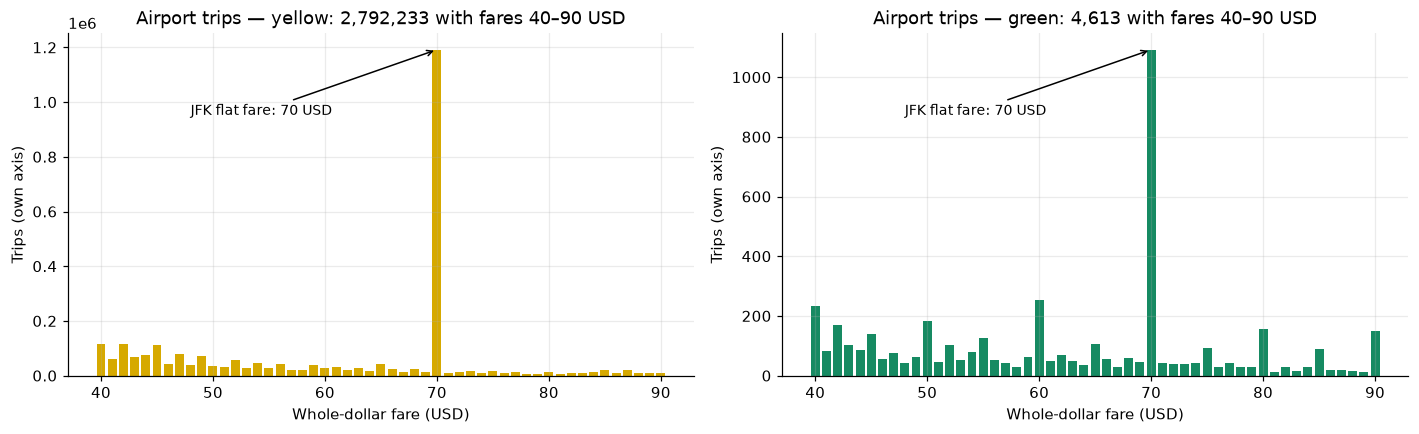

airport trips: 3,797,349; share of Yellow trips: 8.5%


In [11]:
airport = q(f'''
    SELECT taxi_type,
           round(median(fare_amount), 2) AS median_fare,
           round(100.0 * count(*) FILTER (WHERE fare_amount BETWEEN 69.5 AND 70.5) / count(*), 2) AS pct_at_70,
           count(*) AS trips
    FROM {parquet()}
    WHERE is_airport_pu OR is_airport_do GROUP BY 1 ORDER BY 1
''')
display(airport)

hist = q(f'''
    SELECT taxi_type, floor(fare_amount) AS fare_dollar, count(*) AS trips
    FROM {parquet()} WHERE (is_airport_pu OR is_airport_do) AND floor(fare_amount) BETWEEN 40 AND 90
    GROUP BY 1, 2 ORDER BY 1, 2
''')
# Airport volumes differ by ~180x between services, so each panel keeps its own y-axis.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, service in zip(axes, ("yellow", "green")):
    subset = hist[hist.taxi_type == service]
    ax.bar(subset.fare_dollar, subset.trips, color=COLORS[service])
    ax.set(title=f"Airport trips — {service}: {int(subset.trips.sum()):,} with fares 40–90 USD",
           xlabel="Whole-dollar fare (USD)", ylabel="Trips (own axis)")
    peak = subset.loc[subset.trips.idxmax()]
    ax.annotate(f"JFK flat fare: {peak.fare_dollar:.0f} USD", xy=(peak.fare_dollar, peak.trips),
                xytext=(peak.fare_dollar - 22, peak.trips * 0.8),
                arrowprops={"arrowstyle": "->", "color": "black"}, fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "02_airport_flat_fare.png", bbox_inches="tight")
plt.show()
print(f"airport trips: {airport.trips.sum():,}; share of Yellow trips: "
      f"{100*airport.loc[airport.taxi_type=='yellow','trips'].iloc[0]/totals['yellow']:.1f}%")

**Interpretation.** Airport trips show a sharp mass at exactly **\$70** — the JFK flat fare — accounting for
**31.6% of Yellow's 3.78 M airport trips**, alongside an ordinary metered spread for LaGuardia and Newark. A
regression that sees only distance and duration would predict something between the metered and flat regimes and
be wrong for a third of airport trips. Explicit airport flags let a tree split that rule, and airport error
deserves its own line in the evaluation table.

In [12]:
fare_distance = q(f'''
    SELECT pu_borough, do_borough, count(*) AS trips,
           round(median(fare_amount), 2) AS median_fare,
           round(median(haversine_km), 2) AS median_haversine_km
    FROM {parquet()} GROUP BY 1, 2 HAVING count(*) > 50000 ORDER BY trips DESC LIMIT 10
''')
fare_distance["usd_per_km"] = (fare_distance.median_fare / fare_distance.median_haversine_km).round(2)
display(fare_distance.round(2))

,pu_borough,do_borough,trips,median_fare,median_haversine_km,usd_per_km
0,Manhattan,Manhattan,36484199,12.80,2.09,6.12
1,Queens,Manhattan,2189717,59.50,12.48,4.77
2,Queens,Queens,1204405,23.68,5.26,4.50
3,Manhattan,Queens,1132312,44.30,9.45,4.69
4,Manhattan,Brooklyn,985410,31.00,6.53,4.75
5,Brooklyn,Brooklyn,900486,19.50,3.74,5.21
6,Queens,Brooklyn,671081,49.20,13.51,3.64
7,Brooklyn,Manhattan,477110,31.28,6.95,4.50
8,Manhattan,Bronx,245760,34.50,10.98,3.14
9,Brooklyn,Queens,195660,34.50,10.16,3.40


**Interpretation.** Fare per kilometre sits between \$3.14 and \$6.12 across the top borough pairs, and the
ordering is informative: short Manhattan trips are the most expensive per kilometre (\$6.12) because the meter's
minimum charge dominates, while outer-borough long hauls are cheapest per kilometre (\$3.14–\$3.64). This is
exactly the non-linear structure a linear fare model would miss, and it argues for including both distance and
duration, not just one of them.

In [13]:
gaps = q(f'''
    SELECT taxi_type,
           round(median(total_amount - fare_amount), 2) AS median_gap_usd,
           round(quantile_cont(total_amount - fare_amount, 0.90), 2) AS p90_gap_usd,
           round(100.0 * count(*) FILTER (WHERE fare_amount < 0.35 * total_amount) / count(*), 2)
             AS pct_fare_below_35pct_of_total
    FROM {parquet()} WHERE total_amount IS NOT NULL GROUP BY 1 ORDER BY 1
''')
display(gaps)

long_green = q(f'''
    SELECT CASE WHEN duration_min > 60 THEN 'over 60 min' ELSE 'up to 60 min' END AS bucket,
           count(*) AS trips,
           round(median(fare_amount), 2) AS median_fare,
           round(median(total_amount), 2) AS median_total
    FROM {parquet()} WHERE taxi_type = 'green' GROUP BY 1 ORDER BY 1
''')
display(long_green)

,taxi_type,median_gap_usd,p90_gap_usd,pct_fare_below_35pct_of_total
0,green,5.48,13.10,3.94
1,yellow,7.70,13.25,0.93


,bucket,trips,median_fare,median_total
0,over 60 min,8096,5.8,56.73
1,up to 60 min,551128,13.5,19.90


**Interpretation.** The gap between total and metered fare has a median of \$7.70 for Yellow and \$5.48 for
Green, with a 90th percentile near \$13 in both. That gap contains tips, tolls and the congestion charges added
after the ride — discretionary or route-dependent, and therefore **not predictable from pre-trip inputs**.
`total_amount` is kept only for a secondary analysis; `fare_amount` is the honest target.

The second table documents the anomaly flagged in Section 3: Green trips over an hour have a median metered fare
of only \$5.80 against a total of \$56.73. The fare field is unreliable for a small group of long Green records
(their `RatecodeID` is frequently missing). This affects **8,096 trips, 1.4% of Green**, so it does not change
the overall picture, but it explains why long Green trips will show large fare residuals and it is documented
rather than patched by hand.

## 6. Weather and calendar effects

Weather and holidays are the two external signals that plausibly shift supply and demand. Their value is an
empirical question, so they are measured rather than assumed.

,precipitation_band,conditions,trips,median_duration
0,dry,dry,38104770,13.53
1,dry,snowing,5643,15.97
2,heavy,snowing,8391,15.10
3,heavy,"wet, no snow",432737,13.80
4,light,snowing,605976,12.80
5,light,"wet, no snow",4471068,13.90
6,moderate,snowing,105492,12.73
7,moderate,"wet, no snow",1336929,13.87


,band,trips,median_duration
0,below 0C,6166727,12.57
1,0-10C,11541903,13.22
2,10-20C,12996852,13.82
3,20-30C,12337153,14.10
4,30C+,2028371,14.17


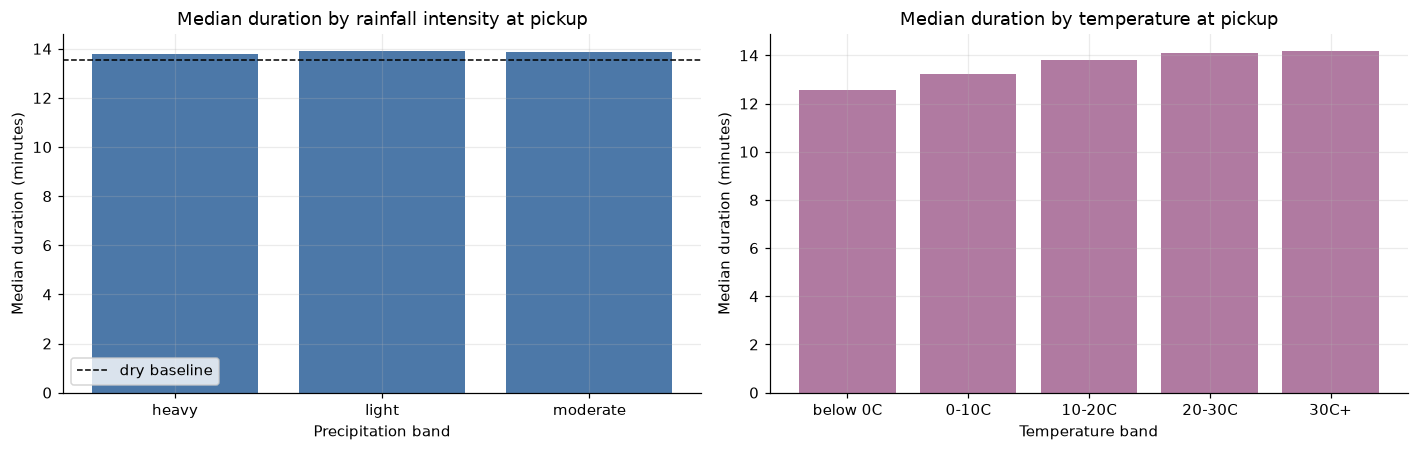

dry median: 13.53
wet medians: {'heavy': 13.8, 'light': 13.9, 'moderate': 13.87}
temp spread: 1.6


In [14]:
weather = q(f'''
    SELECT CASE
             WHEN precipitation_mm = 0 THEN 'dry'
             WHEN precipitation_mm < 1 THEN 'light'
             WHEN precipitation_mm < 3 THEN 'moderate'
             ELSE 'heavy' END AS precipitation_band,
           CASE
             WHEN snowfall_cm > 0 THEN 'snowing'
             WHEN precipitation_mm > 0 THEN 'wet, no snow'
             ELSE 'dry' END AS conditions,
           count(*) AS trips, round(median(duration_min), 2) AS median_duration
    FROM {parquet()} GROUP BY 1, 2 ORDER BY 1, 2
''')
display(weather)

temperature = q(f'''
    SELECT CASE
             WHEN temperature_c < 0 THEN 'below 0C'
             WHEN temperature_c < 10 THEN '0-10C'
             WHEN temperature_c < 20 THEN '10-20C'
             WHEN temperature_c < 30 THEN '20-30C'
             ELSE '30C+' END AS band,
           count(*) AS trips, round(median(duration_min), 2) AS median_duration
    FROM {parquet()} GROUP BY 1
    ORDER BY min(temperature_c)
''')
display(temperature)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
dry = weather[(weather.conditions == "dry")].groupby("precipitation_band").median_duration.mean()
wet = weather[weather.conditions == "wet, no snow"]
axes[0].bar(wet.precipitation_band, wet.median_duration, color="#4C78A8")
axes[0].axhline(weather.loc[(weather.conditions == "dry"), "median_duration"].iloc[0],
                color="black", ls="--", lw=1, label="dry baseline")
axes[0].set(title="Median duration by rainfall intensity at pickup", xlabel="Precipitation band",
            ylabel="Median duration (minutes)")
axes[0].legend()
axes[1].bar(temperature.band, temperature.median_duration, color="#B07AA1")
axes[1].set(title="Median duration by temperature at pickup", xlabel="Temperature band",
            ylabel="Median duration (minutes)")
fig.tight_layout()
fig.savefig(FIGURES / "02_weather_effects.png", bbox_inches="tight")
plt.show()

print("dry median:", float(weather.loc[weather.conditions == "dry", "median_duration"].iloc[0]))
print("wet medians:", wet.set_index("precipitation_band").median_duration.to_dict())
print("temp spread:", round(float(temperature.median_duration.max() - temperature.median_duration.min()), 2))

**Interpretation.** Weather is a real but **small** effect, and not monotone in intensity. Dry hours have a median
of 13.53 minutes; light rain 13.90, moderate 13.87 and heavy 13.80 — roughly half a minute regardless of how hard
it rains. Snow is noisier still, because snow hours are rare (5.6 k trips in the dry-snowfall band) and
concentrated in specific months.

Temperature spans 12.57 minutes below 0 °C to 14.17 at 30 °C+, but this is confounded: sub-zero hours are mostly
late nights in January, while 30 °C hours are summer afternoons. Temperature therefore partly proxies for season
and hour, both of which are already features.

The conclusion is deliberately unexciting: include weather because it is cheap and physically plausible, but
expect SHAP to attribute little to it — and do not be surprised if it ranks below zone and hour.

In [15]:
calendar = q(f'''
    SELECT is_holiday, is_rush_hour, is_weekend, count(*) AS trips,
           round(median(duration_min), 2) AS median_duration,
           round(median(fare_amount), 2) AS median_fare
    FROM {parquet()} GROUP BY 1, 2, 3 ORDER BY 1, 2, 3
''')
display(calendar)

holiday_zone = q(f'''
    SELECT pu_borough,
           round(median(CASE WHEN is_holiday THEN duration_min END), 2) AS holiday_median,
           round(median(CASE WHEN NOT is_holiday THEN duration_min END), 2) AS regular_median,
           count(*) FILTER (WHERE is_holiday) AS holiday_trips
    FROM {parquet()} GROUP BY 1 HAVING holiday_trips > 1000 ORDER BY 1
''')
holiday_zone["delta_minutes"] = (holiday_zone.holiday_median - holiday_zone.regular_median).round(2)
display(holiday_zone)

weekday = calendar[(~calendar.is_weekend) & (~calendar.is_holiday)]
print("weekday rush vs non-rush median:",
      weekday.set_index("is_rush_hour").median_duration.to_dict())
print("holiday share of trips:", round(100 * calendar[calendar.is_holiday].trips.sum() / calendar.trips.sum(), 2), "%")

,is_holiday,is_rush_hour,is_weekend,trips,median_duration,median_fare
0,False,False,False,20783500,13.75,14.34
1,False,False,True,9646053,13.03,14.85
2,False,True,False,10481112,13.88,14.20
3,False,True,True,3157811,13.38,14.49
4,True,False,False,721832,12.50,13.88
5,True,True,False,280698,12.27,13.50


,pu_borough,holiday_median,regular_median,holiday_trips,delta_minutes
0,Bronx,17.23,23.38,9817,-6.15
1,Brooklyn,20.28,22.52,43174,-2.24
2,Manhattan,10.98,12.45,819754,-1.47
3,Queens,25.62,31.55,129642,-5.93


weekday rush vs non-rush median: {False: 13.75, True: 13.88}
holiday share of trips: 2.22 %


**Interpretation.** Two findings, one expected and one not.

**Holidays make the city faster.** Holiday trips have a median of 12.27–12.50 minutes against 13.75–13.88 on
ordinary weekdays, and the effect is largest outside Manhattan: the Bronx is 6.2 minutes faster and Queens 5.9,
against 1.5 in Manhattan. Reduced commuting overwhelms any holiday demand spike.

**Rush hour barely moves the median.** On weekdays, rush-hour trips have a median of 13.88 minutes against 13.75
outside rush hour — a 0.13-minute difference. That is not a typo: the rush-hour flag described by 7–10 am and
4–7 pm mixes slow hours with merely busy ones, and it is too coarse to carry the effect the heat map shows. The
hourly and hour × weekday features are the right representation; `is_rush_hour` is kept mainly as a cheap
interpretable summary, not as the model's main time signal.

## 7. Yellow versus Green

The two services differ in volume, coverage and fare structure. This section quantifies all three in one table,
because it underpins the decision to report results per service.

In [16]:
comparison = q(f'''
    SELECT taxi_type,
           count(*) AS trips,
           round(100.0 * count(*) FILTER (WHERE pu_borough = 'Manhattan') / count(*), 1) AS pct_manhattan_pickup,
           round(100.0 * count(*) FILTER (WHERE is_cbd_pu) / count(*), 1) AS pct_cbd_pickup,
           round(100.0 * count(*) FILTER (WHERE is_airport_pu OR is_airport_do) / count(*), 1) AS pct_airport,
           round(100.0 * count(*) FILTER (WHERE cross_borough) / count(*), 1) AS pct_cross_borough,
           round(median(haversine_km), 2) AS median_haversine_km,
           round(median(duration_min), 1) AS median_duration,
           round(median(fare_amount), 2) AS median_fare,
           round(median(fare_amount) / median(haversine_km), 2) AS median_usd_per_km
    FROM {parquet()} GROUP BY 1 ORDER BY 1
''')
display(comparison.set_index("taxi_type").T)

ratio = comparison.set_index("taxi_type")
print(f"Yellow carries {ratio.loc['yellow','trips'] / ratio.loc['green','trips']:.1f}x the trips of Green")
print(f"Green median duration is {100*(ratio.loc['green','median_duration']/ratio.loc['yellow','median_duration']-1):+.1f}% vs Yellow")

taxi_type,green,yellow
trips,559224.00,44511782.00
pct_manhattan_pickup,61.50,86.70
pct_cbd_pickup,0.50,61.40
pct_airport,3.70,8.50
pct_cross_borough,12.40,14.10
median_haversine_km,2.74,2.50
median_duration,12.80,13.60
median_fare,13.50,14.21
median_usd_per_km,4.92,5.69


Yellow carries 79.6x the trips of Green
Green median duration is -5.9% vs Yellow


**Interpretation.** Yellow is a Manhattan-core and airport service: **86.7% of pickups are in Manhattan, 61.4%
inside the CBD and 8.5% involve an airport**. Green is not simply "outer borough" — **61.5% of its pickups are in
Manhattan** — but only **0.5% are in the CBD**, because Boro Taxis may not take street hails south of the Upper
Manhattan boundary. Green's Manhattan is East Harlem, Morningside Heights and Washington Heights, not Midtown.

The geometric surprise is that Green trips are **longer in straight-line distance** (median 2.74 km against
Yellow's 2.50) yet **faster in time** (12.8 against 13.6 minutes), i.e. it moves through less congested streets at
a lower fare per kilometre (\$4.92 against \$5.69). Green also crosses borough boundaries about as often as
Yellow (12.4% against 14.1%) despite carrying 1/80th of the volume.

For modelling this means the pooled distribution is a mixture of two different populations, and `taxi_type`
carries genuine information — but it is a proxy for geography rather than a causal service effect, which is worth
stating explicitly in any interpretation of its importance.

## 8. Implications for modelling

The observations above translate into concrete decisions. This table records how much the typical duration moves
when trips are grouped one way, so the modelling notebooks can be read against the evidence that motivated them.

In [17]:
spread = q(f'''
    SELECT 'pickup borough' AS grouping,
           round(max(med) - min(med), 2) AS spread_minutes,
           count(*) AS buckets
    FROM (SELECT pu_borough, median(duration_min) AS med FROM {parquet()} GROUP BY 1)
    UNION ALL
    SELECT 'hour', round(max(med) - min(med), 2), count(*) FROM
      (SELECT pickup_hour_of_day, median(duration_min) AS med FROM {parquet()} GROUP BY 1)
    UNION ALL
    SELECT 'month', round(max(med) - min(med), 2), count(*) FROM
      (SELECT month, median(duration_min) AS med FROM {parquet()} GROUP BY 1)
    UNION ALL
    SELECT 'day_of_week', round(max(med) - min(med), 2), count(*) FROM
      (SELECT day_of_week, median(duration_min) AS med FROM {parquet()} GROUP BY 1)
    UNION ALL
    SELECT 'taxi type', round(max(med) - min(med), 2), count(*) FROM
      (SELECT taxi_type, median(duration_min) AS med FROM {parquet()} GROUP BY 1)
    UNION ALL
    SELECT 'precipitation (wet vs dry)', round(max(med) - min(med), 2), count(*) FROM
      (SELECT CASE WHEN precipitation_mm = 0 THEN 'dry' ELSE 'wet' END AS b,
              median(duration_min) AS med FROM {parquet()} GROUP BY 1)
    ORDER BY spread_minutes DESC
''')
display(spread)

overall = q(f"SELECT round(median(duration_min), 2) AS overall_median, "
            f"round(stddev_samp(duration_min), 2) AS sd FROM {parquet()}").iloc[0]
print(f"Overall median duration {overall.overall_median} minutes, standard deviation {overall.sd} minutes")

,grouping,spread_minutes,buckets
0,pickup borough,27.12,6
1,hour,3.25,24
2,month,3.13,12
3,day_of_week,1.20,7
4,taxi type,0.82,2
5,precipitation (wet vs dry),0.23,2


Overall median duration 13.57 minutes, standard deviation 13.58 minutes


**Interpretation.** Grouping by **pickup borough** moves the median duration by 27 minutes — far more than hour
(3.3), month (3.1) or weekday (1.2) — and weather moves it by 0.2. Geography is the dominant signal, which matches
the permutation importance measured in Notebook 01, where pickup zone ranked first.

But every grouping is small next to the spread of individual trips (a standard deviation of roughly 13–14
minutes): no single variable explains much, and the model has to combine place, time and their interaction. It
also sets a realistic expectation — with no access to the route actually driven, an R² near 0.3 is the plausible
ceiling, not a failure.

**Decisions carried into Phase 4:**

1. Build cyclical hour and weekday encodings plus month, and let trees learn the hour × weekday interaction.
2. Keep both zone identifiers and zone-derived geometry; handle unseen zones explicitly, since the top zones hold
   a large share of volume and rare zones will be missing from short training windows.
3. Keep airport and CBD flags — they explain both the flat-fare spike and the Manhattan concentration — and add
   the borough pair.
4. Keep weather and holidays, with the documented caveat that their marginal effect is small (≈0.3 min for rain)
   and partly collinear with season and hour.
5. Use MAE and median absolute error as headline duration metrics with RMSE reported; for fares, MAE/RMSE with
   MAPE only above a fare floor.
6. Expect Nov–Dec test months to be slower than training months; report that gap rather than tune it away.
7. Never use `trip_distance`, `fare_amount`, `total_amount`, drop-off time or any surcharge as a predictor. The
   fare and duration sections show how strong those signals are, which is exactly why they would leak.

## 9. Conclusions

- Demand is evening-heavy for Yellow and earlier for Green; duration peaks in the **afternoon**, before volume
  peaks, so volume and slowness need separate representations.
- Median duration rises 27% from January to December, so the chronological split puts the slowest months in the
  test window. That is a finding to report, not to hide.
- Duration and fare are right-skewed; median metrics and a log-target experiment are warranted.
- Geography dominates: pickup borough alone shifts the median by 27 minutes, more than hour, month or weather.
  Within that, Green is Upper Manhattan plus the outer boroughs, not "outer boroughs only".
- Airport flat fares are structural (31.6% of Yellow airport trips at exactly \$70) and need explicit handling.
- Weather and holidays matter but are secondary; rush hour as a binary flag is nearly useless on its own, because
  the true time signal lives in hour × weekday.
- A small group of long Green trips (1.4% of Green) has an unreliable fare field; documented, not hand-patched.